In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем логи событий
events_df = pd.read_csv("../events.csv")
events_df.columns = [c.lower().strip() for c in events_df.columns]

print("Размер датасета events:", events_df.shape)
print("\Типы данных и пропуски:")
print(events_df.info())

print("\nПервые 5 строк:")
display(events_df.head())

print("\nРаспределение типов событий (event):")
print(events_df['event'].value_counts(dropna=False))

Размер датасета events: (2756101, 5)
\Типы данных и пропуски:
<class 'pandas.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          str    
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), str(1)
memory usage: 105.1 MB
None

Первые 5 строк:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Распределение типов событий (event):
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


In [4]:
# 1. Приводим timestamp к читаемому формату
events_df['datetime'] = pd.to_datetime(events_df['timestamp'], unit='ms', errors='coerce')

# 2. Удаляем явные полные дубликаты строк
initial_len = len(events_df)
events_df = events_df.drop_duplicates()
print(f"Удалено полных дубликатов: {initial_len - len(events_df)}")

# 3. Фильтрация ботов (пользователей с аномально высоким числом событий, например, > 5000 за весь период)
visitor_activity = events_df['visitorid'].value_counts()
suspicious_visitors = visitor_activity[visitor_activity > 5000].index
print(f"Обнаружено подозрительных ботов-визитеров (>5000 событий): {len(suspicious_visitors)}")

# Удаляем ботов из датасета
events_df = events_df[~events_df['visitorid'].isin(suspicious_visitors)]

# 4. Проверяем пропуски в ключевых колонках
print("\nПропущенные значения после фильтрации:")
print(events_df.isna().sum())

Удалено полных дубликатов: 460
Обнаружено подозрительных ботов-визитеров (>5000 событий): 1

Пропущенные значения после фильтрации:
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2725986
datetime               0
dtype: int64


In [6]:
# Читаем небольшую выборку или часть файла для анализа свойств
item_props_1 = pd.read_csv("../item_properties_part1.csv", nrows=1000000)
item_props_1.columns = [c.lower().strip() for c in item_props_1.columns]

print("Уникальные свойства (первые 20):", item_props_1['property'].unique()[:20])
print("\nКоличество уникальных товаров в файле свойств:", item_props_1['itemid'].nunique())

# Посмотрим на распределение основных свойств вроде 'categoryid' и 'available'
cat_props = item_props_1[item_props_1['property'] == 'categoryid']
print(f"Доля записей с categoryid в выборке: {len(cat_props) / len(item_props_1):.2%}")

Уникальные свойства (первые 20): <StringArray>
['categoryid',        '888',        '400',        '790',        '917',
  'available',        '213',          '6',        '202',        '451',
        '227',        '839',          '0',       '1022',        '566',
        '159',        '830',        '134',         '19',        '216']
Length: 20, dtype: str

Количество уникальных товаров в файле свойств: 330357
Доля записей с categoryid в выборке: 3.85%


Размер обучающей выборки: (2670609, 11)

Распределение целевой переменной (target):
target
0    0.986655
1    0.013345
Name: proportion, dtype: float64


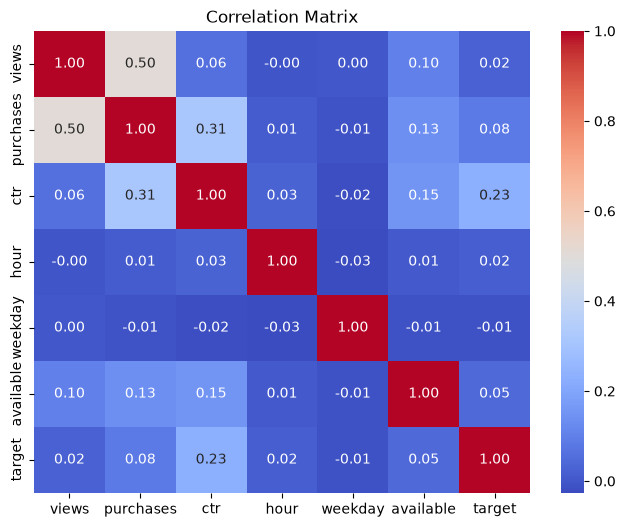

In [9]:
# Если вы уже запускали prepare_features.py, исследуем полученный train-датасет:
train_df = pd.read_parquet("../data_for_training.parquet")

print("Размер обучающей выборки:", train_df.shape)
print("\nРаспределение целевой переменной (target):")
print(train_df['target'].value_counts(normalize=True))

# Корреляционная матрица числовых фич
plt.figure(figsize=(8, 6))
sns.heatmap(train_df[['views', 'purchases', 'ctr', 'hour', 'weekday', 'available', 'target']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()